In [ ]:
# Instal libraries
!pip install segmentation-models-pytorch
!pip install roboflow
!pip install albumentations --upgrade
!pip install torchvision
!pip install pycocotools

In [ ]:
# Connect Google Colab notebook with Google Drive
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
# Unzip dataset from Google Drive to Google Colab environment
!unzip "/content/drive/MyDrive/Ancient Foundations.v1-v1_dataset.coco-segmentation.zip" -d /content/

Archive:  /content/drive/MyDrive/Ancient Foundations.v1-v1_dataset.coco-segmentation.zip
  inflating: /content/README.dataset.txt  
  inflating: /content/README.roboflow.txt  
   creating: /content/train/
 extracting: /content/train/001_png.rf.52e0fe7d84e66aa75041d2f09ff8e3e2.jpg  
 extracting: /content/train/001_png.rf.9b9b3d9a4232ea70fc07e056e0852484.jpg  
 extracting: /content/train/001_png.rf.9f179d7600f8dc4ae6899a60fd92f69b.jpg  
 extracting: /content/train/002_png.rf.3a831b76f1bbd3b4312b4b0972be3f16.jpg  
 extracting: /content/train/002_png.rf.56e43d0175c174668166d92e6ddc863e.jpg  
 extracting: /content/train/002_png.rf.99e17c88baae5f31b05987a3029bf664.jpg  
 extracting: /content/train/003_png.rf.1f71cb2e9a7dd60a531dbb8300f8f4ef.jpg  
 extracting: /content/train/003_png.rf.d66c75800428a64e0162afc24154f7fa.jpg  
 extracting: /content/train/003_png.rf.f17c120ef4f4497c2a01fe24bc0a5a00.jpg  
 extracting: /content/train/004_png.rf.0e92a83b41dbecaa2aef60ff1edebce2.jpg  
 extracting: /c

In [ ]:
# Import all necessary libraries
import os
import cv2
import numpy as np
import torch
from torch.utils.data import Dataset
from pycocotools.coco import COCO
from PIL import Image
import matplotlib.pyplot as plt

# Create a custom dataset class to read COCO-style segmentation data
class COCOSegmentationDataset(Dataset):
    def __init__(self, images_dir, annotation_path, transform=None):

        # images_dir: folder where all input images are stored
        # annotation_path: path to the COCO-style JSON annotation file
        self.images_dir = images_dir

        # Load COCO annotations
        self.coco = COCO(annotation_path)

        # Get list of all image IDs
        self.image_ids = list(self.coco.imgs.keys())
        self.transform = transform

# Returns the total number of images in the dataset
    def __len__(self):
        return len(self.image_ids)

# Load one image and its segmentation mask by index
    def __getitem__(self, idx):

        # Get the image ID and its metadata
        image_id = self.image_ids[idx]
        image_info = self.coco.loadImgs(image_id)[0]

        # Build the full path to the image file
        image_path = os.path.join(self.images_dir, image_info['file_name'])

        # Open the image and convert it to RGB format
        image = np.array(Image.open(image_path).convert("RGB"))

        # Get all annotation IDs for this image
        ann_ids = self.coco.getAnnIds(imgIds=image_id)

        # Load annotation objects using the annotation IDs
        anns = self.coco.loadAnns(ann_ids)

        # Create a blank mask with the same height and width as the image
        mask = np.zeros((image_info['height'], image_info['width']), dtype=np.uint8)

        # Combine all object masks into one using the maximum pixel value
        for ann in anns:
            mask = np.maximum(mask, self.coco.annToMask(ann))

        # Normalize the image values to the range [0, 1]
        image = image / 255.0

        # Change the image shape from (H, W, C) to (C, H, W)
        image = np.transpose(image, (2, 0, 1))

        # Return the image and its mask as PyTorch tensors
        return torch.tensor(image, dtype=torch.float32), torch.tensor(mask, dtype=torch.float32).unsqueeze(0)

loading annotations into memory...
Done (t=0.01s)
creating index...
index created!


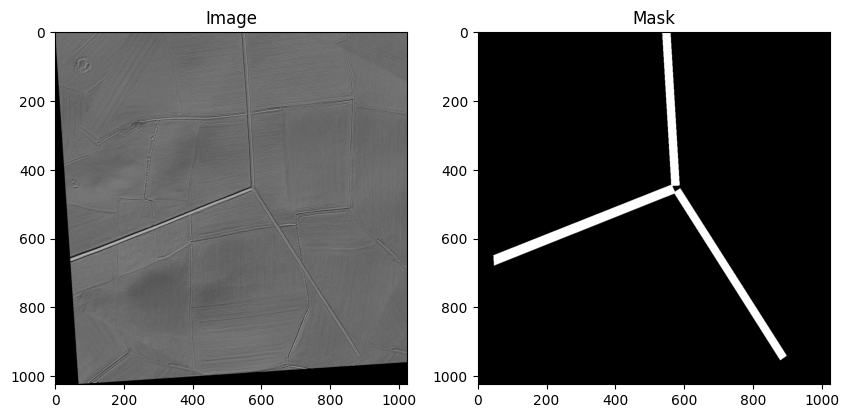

In [ ]:
# Load the COCO segmentation dataset using the custom class
dataset = COCOSegmentationDataset(

    # Path to folder containing training images
    images_dir="/content/train",

    # Path to COCO-format annotation JSON file
    annotation_path="/content/train/_annotations.coco.json"
)

# Select one sample (image + mask) from the dataset for visualization
# Load the first image and its corresponding mask
image, mask = dataset[0]

# Display the image and its mask side-by-side using matplotlib
# Set the figure size
plt.figure(figsize=(10,5))

# Show the input image
plt.subplot(1,2,1)

# Convert image from (C, H, W) to (H, W, C) for display
plt.imshow(image.permute(1, 2, 0))
plt.title("Image")

# Show the ground truth mask
plt.subplot(1,2,2)

# Remove channel dimension and show as grayscale
plt.imshow(mask.squeeze(), cmap="gray")
plt.title("Mask")

# Show both plots
plt.show()

In [ ]:
# Import the segmentation_models_pytorch library
import segmentation_models_pytorch as smp

# Create a U-Net model with a ResNet34 encoder
model = smp.Unet(
    encoder_name="resnet34",        # Use ResNet34 as the encoder backbone
    encoder_weights="imagenet",     # Load pretrained weights from ImageNet
    in_channels=3,                  # Input has 3 channels (RGB image)
    classes=1                       # Output has 1 class (for binary segmentation)
)

# Set the device to GPU if available, otherwise use CPU
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")


# Move the model to the selected device
model.to(device)

/usr/local/lib/python3.11/dist-packages/huggingface_hub/utils/_auth.py:94: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(


config.json:   0%|          | 0.00/156 [00:00<?, ?B/s]

model.safetensors:   0%|          | 0.00/87.3M [00:00<?, ?B/s]

Unet(
  (encoder): ResNetEncoder(
    (conv1): Conv2d(3, 64, kernel_size=(7, 7), stride=(2, 2), padding=(3, 3), bias=False)
    (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (relu): ReLU(inplace=True)
    (maxpool): MaxPool2d(kernel_size=3, stride=2, padding=1, dilation=1, ceil_mode=False)
    (layer1): Sequential(
      (0): BasicBlock(
        (conv1): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
        (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
        (relu): ReLU(inplace=True)
        (conv2): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
        (bn2): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      )
      (1): BasicBlock(
        (conv1): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
        (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track

In [ ]:
from torch.utils.data import DataLoader, random_split

# Split the dataset into training and validation sets (80/20 split)
train_size = int(0.8 * len(dataset))  # 80% of the total dataset for training
val_size = len(dataset) - train_size  # Remaining 20% for validation

# Randomly split the dataset into training and validation subsets
train_dataset, val_dataset = random_split(dataset, [train_size, val_size])

# Create DataLoaders to load data in batches
train_loader = DataLoader(train_dataset, batch_size=4, shuffle=True)  # Shuffle during training
val_loader = DataLoader(val_dataset, batch_size=4)                    # No shuffle needed for validation

In [ ]:
import torch.nn as nn
import torch.optim as optim

# Loss function for training
# This loss is good for binary problems (like "foundation" vs. "not foundation")
loss_fn = nn.BCEWithLogitsLoss()

# Optimizer for training
# Adam helps the model learn better and faster
optimizer = optim.Adam(model.parameters(), lr=1e-4)  # Learning rate is 0.0001

In [ ]:
# Train the model for 5 times
for epoch in range(5):

    # Tell the model we are training it
    model.train()

    # Start loss from zero
    train_loss = 0

    for images, masks in train_loader:  # Go through each group of images
        images = images.to(device)      # Move images to GPU or CPU
        masks = masks.to(device)        # Move masks to GPU or CPU

        outputs = model(images)         # Get model's output
        loss = loss_fn(outputs, masks)  # Calculate how wrong the output is

        optimizer.zero_grad()           # Clear old learning steps
        loss.backward()                 # Learn from the mistake
        optimizer.step()                # Update the model

        train_loss += loss.item()       # Add this loss to total

    # Find average loss
    avg_loss = train_loss / len(train_loader)

    # Print result
    print(f"Epoch {epoch+1} - Training Loss: {avg_loss:.4f}")

Epoch 1 - Training Loss: 0.3836
Epoch 2 - Training Loss: 0.2095
Epoch 3 - Training Loss: 0.1581
Epoch 4 - Training Loss: 0.1242
Epoch 5 - Training Loss: 0.1123


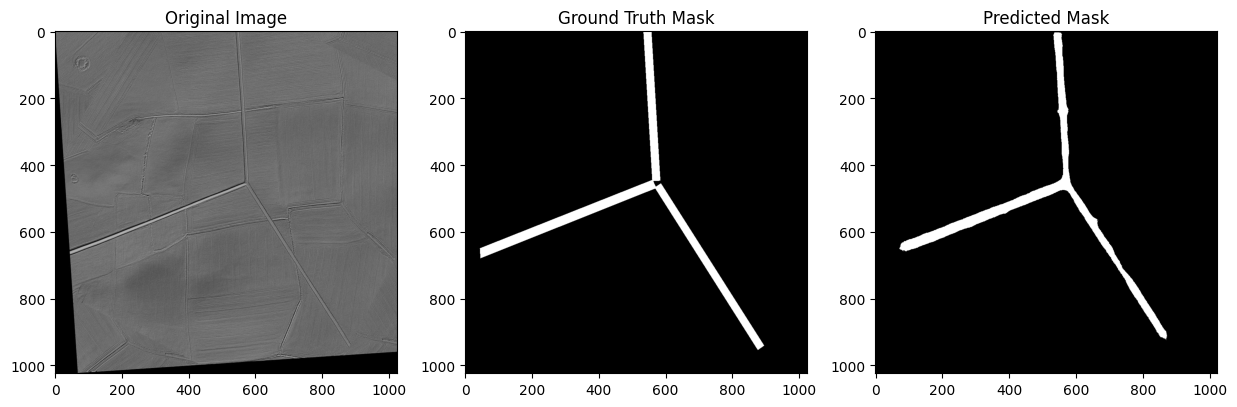

In [ ]:
# Set the model to test mode
model.eval()

# Get 1 image and its real mask from the dataset
image, mask = dataset[0]

# Add batch size (needed for model) and move image to GPU or CPU
image_input = image.unsqueeze(0).to(device)

with torch.no_grad():
    pred_mask = model(image_input)          # Get output from model
    pred_mask = torch.sigmoid(pred_mask)    # Make values between 0 and 1
    pred_mask = (pred_mask > 0.5).float()   # Make values 0 or 1

# Show the image, real mask, and model mask
plt.figure(figsize=(15,5))  # Set the size of the window

# Show the original input image
plt.subplot(1,3,1)
plt.imshow(image.permute(1, 2, 0).cpu())  # Change shape to show image
plt.title("Original Image")

# Show the real mask from the dataset
plt.subplot(1,3,2)
plt.imshow(mask.squeeze(), cmap="gray")
plt.title("Ground Truth Mask")

# Show the mask made by the model
plt.subplot(1,3,3)
plt.imshow(pred_mask.squeeze().cpu(), cmap="gray")
plt.title("Predicted Mask")

# Show All images
plt.show()

In [ ]:
# Save the trained model to a file
torch.save(model.state_dict(), "/content/ancient_foundation_unet.pth")

In [ ]:
# Move model file to your Google Drive for permanent storage
!cp /content/ancient_foundation_unet.pth /content/drive/MyDrive/

In [ ]:
# Install the segmentation_models_pytorch library
# -q means quiet mode (less output while installing)
!pip install -q segmentation-models-pytorch

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 154.8/154.8 kB 4.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 363.4/363.4 MB 2.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 13.8/13.8 MB 125.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 24.6/24.6 MB 96.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 883.7/883.7 kB 53.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 664.8/664.8 MB 2.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 211.5/211.5 MB 5.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 56.3/56.3 MB 17.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 127.9/127.9 MB 7.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 207.5/207.5 MB 5.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 21.1/21.1 MB 51.1 MB/s eta 0:00:00


In [ ]:
# Import all necessary libraries
import torch
import segmentation_models_pytorch as smp
import matplotlib.pyplot as plt

In [ ]:
# Check if GPU is available, otherwise use CPU
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# Define U-Net model with ResNet34 encoder
model = smp.Unet(
    encoder_name="resnet34",      # Use ResNet34 for the encoder
    encoder_weights="imagenet",   # Use pre-trained weights from ImageNet
    in_channels=3,                # Input has 3 channels (RGB image)
    classes=1                     # Output has 1 class (for binary mask)
)

# Load the trained model from Google Drive
model.load_state_dict(torch.load("/content/drive/MyDrive/ancient_foundation_unet.pth", map_location=device))
model.to(device)  # Move the model to GPU or CPU
model.eval()      # Set the model to test mode (not training)

/usr/local/lib/python3.11/dist-packages/huggingface_hub/utils/_auth.py:94: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(


config.json:   0%|          | 0.00/156 [00:00<?, ?B/s]

model.safetensors:   0%|          | 0.00/87.3M [00:00<?, ?B/s]

Unet(
  (encoder): ResNetEncoder(
    (conv1): Conv2d(3, 64, kernel_size=(7, 7), stride=(2, 2), padding=(3, 3), bias=False)
    (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (relu): ReLU(inplace=True)
    (maxpool): MaxPool2d(kernel_size=3, stride=2, padding=1, dilation=1, ceil_mode=False)
    (layer1): Sequential(
      (0): BasicBlock(
        (conv1): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
        (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
        (relu): ReLU(inplace=True)
        (conv2): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
        (bn2): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      )
      (1): BasicBlock(
        (conv1): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
        (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track

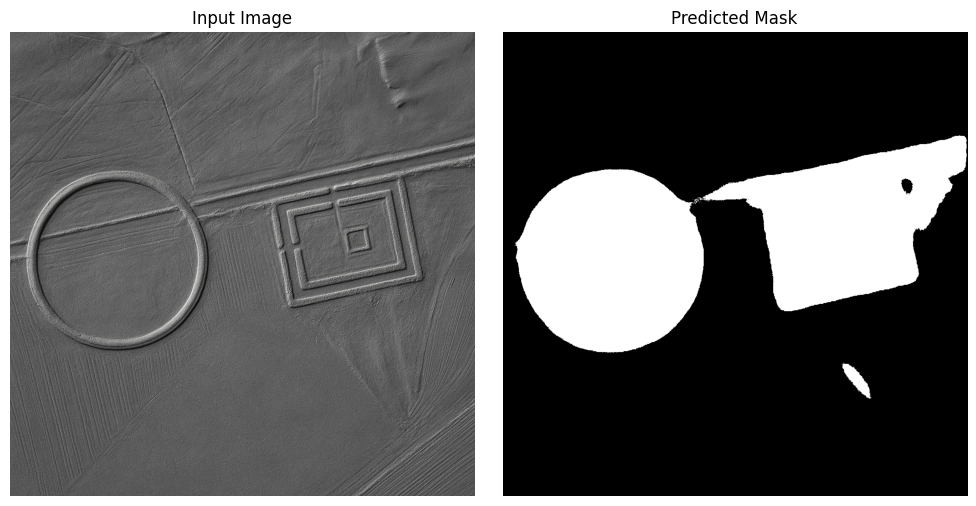

In [ ]:
import matplotlib.pyplot as plt
import torch
import numpy as np
import cv2  # For image loading

# Path to your test image in Google Drive
image_path = "/content/drive/MyDrive/sample_images/009.png"

# Load image using OpenCV
img = cv2.imread(image_path)

# Change image color from BGR to RGB (because OpenCV uses BGR)
img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

# Normalize and convert to tensor
img_tensor = torch.from_numpy(img).float() / 255.0

# Change shape from HWC (height, width, channels) to CHW
img_tensor = img_tensor.permute(2, 0, 1)

# Add batch size and move image to GPU or CPU
image_input = img_tensor.unsqueeze(0).to(device)

# Use model to make prediction
with torch.no_grad():
    output = model(image_input)                                   # Get result from model
    pred_mask = torch.sigmoid(output).squeeze().cpu().numpy()     # Make values between 0 and 1
    pred_mask = (pred_mask > 0.5).astype('uint8')                 # Make 0 or 1 (black or white)

# Change image back to normal shape for display
image_np = img_tensor.permute(1, 2, 0).cpu().numpy()

# Show input image and predicted mask side by side
plt.figure(figsize=(10, 5))

# Show original image
plt.subplot(1, 2, 1)
plt.title("Input Image")
plt.imshow(image_np)
plt.axis("off")

# Show predicted mask
plt.subplot(1, 2, 2)
plt.title("Predicted Mask")
plt.imshow(pred_mask, cmap="gray")
plt.axis("off")

# Show the full plot
plt.tight_layout()
plt.show()
